# 🚑 EMS Capacity Planning — Queueing Theory
**Ứng dụng Lý thuyết Hàng đợi để Biến Dự báo Nhu cầu $\hat{\lambda}(t)$ thành Số lượng Xe Cứu thương Cần thiết $s(t)$**

---

### 1. Đặt vấn đề
Trong quản lý dịch vụ khẩn cấp (Emergency Medical Services — EMS):
* Dự báo số lượng cuộc gọi $\hat{\lambda}(t)$ chỉ là bước đầu.
* **Yêu cầu thực tiễn của nhà điều hành**: Cần bố trí **bao nhiêu xe trực chiến mỗi giờ** $s(t)$?
  * Nếu bố trí **quá ít**: Bệnh nhân phải chờ đợi lâu, nguy cơ tử vong tăng cao, hoặc phải xin chi viện từ quận khác (mutual aid).
  * Nếu bố trí **quá nhiều**: Lãng phí chi phí vận hành, ngân sách và nhân lực y tế.

### 2. Cơ sở Lý thuyết
#### A. Định luật Little — Tính tải Erlang $a(t)$:
Tải phục vụ trung bình (tính bằng đơn vị Erlang, đại diện cho số xe bận cùng lúc):
$$a(t) = \hat{\lambda}(t) \times u \times E[S]$$
* $\hat{\lambda}(t)$: Tốc độ cuộc gọi đến tại giờ $t$ (cuộc gọi/giờ).
* $u$: Số xe cứu thương trung bình được điều phối cho mỗi cuộc gọi (xe/cuộc gọi).
* $E[S]$: Thời gian bận trung bình của một xe trong một ca cấp cứu (giờ/xe).

#### B. Mô hình Hàng đợi EMS: M/M/s/s Loss System (Erlang B)
* Hệ thống EMS là mô hình **không xếp hàng chờ vô hạn**: Khi tất cả $s$ xe đều bận, cuộc gọi khẩn cấp sẽ bị từ chối hoặc chuyển tuyến sang trạm/đơn vị khác (blocking/loss).
* Ta áp dụng **3 tiêu chuẩn vận hành** để xác định số xe $s(t)$:
  1. **Tiêu chí 1 — Hệ số sử dụng $\rho \le 0.80$**: $s = \lceil a / 0.80 \rceil$. Khi $\rho > 0.85$, hệ thống rơi vào vùng bất ổn định phi tuyến.
  2. **Tiêu chí 2 — Công thức mất cuộc gọi Erlang B $\le 5\%$**: Xác suất tất cả $s$ xe đều bận $B(s, a) \le 0.05$.
  3. **Tiêu chí 3 — Phân vị Poisson 98%**: Do số xe bận tại bất kỳ thời điểm nào tuân theo phân phối Poisson($a$), ta chọn $s = \lceil a + 2.05 \sqrt{a} \rceil$ để bảo đảm đủ xe trong $98\%$ tình huống ngẫu nhiên.


In [1]:
import sys, os

ROOT = os.path.abspath("..")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

from ems.models.lstm.config     import DATA_DIR, OUTPUT_DIR, TARGET_COL, N_FEATURES,                            HIDDEN_SIZE, NUM_LAYERS, DROPOUT, BATCH_SIZE
from ems.models.lstm.preprocess import build_dataloaders
from ems.models.lstm.model      import build_model
from ems.models.lstm.train      import load_checkpoint
from ems.models.lstm.evaluate   import predict, compute_metrics, print_metrics, naive_baseline
from ems.queuing    import (
    estimate_service_params,
    compute_erlang_load,
    vehicles_utilization,
    vehicles_erlang_b,
    vehicles_poisson_quantile,
    forecast_to_vehicles,
    summarize_vehicles,
    print_summary,
    plot_vehicles_timeline,
    plot_hourly_profile,
    plot_model_comparison,
)

print("Environment ready! Imports successful.")


Environment ready! Imports successful.


## Bước 1: Nạp Dữ liệu & Kết quả Dự báo $\hat{\lambda}(t)$
Notebook này tự động nạp mô hình LSTM đã huấn luyện (`vanilla_seq24`), thực hiện inference trên tập Test, và tạo mô hình cơ sở Naive Lag-1 để đối chiếu.

In [11]:
train_dl, val_dl, test_dl, feat_scaler, tgt_scaler = build_dataloaders(
    seq_len=24, batch_size=BATCH_SIZE, verbose=False
)

model_24 = build_model("vanilla", n_features=N_FEATURES,
                       hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS,
                       dropout=DROPOUT)
load_checkpoint(model_24, run_name="vanilla_seq24")

# Dự báo trên Test set
y_true_24, y_pred_24 = predict(model_24, test_dl, tgt_scaler)
metrics_24 = compute_metrics(y_true_24, y_pred_24)
print_metrics(metrics_24, run_name="LSTM seq=24 Test Set")

# Naive Baseline (Lag-1)
y_test_raw = pd.read_csv(os.path.join(DATA_DIR, "y_test.csv"))[TARGET_COL].values
y_pred_naive_full = np.roll(y_test_raw, 1)
y_pred_naive_full[0] = y_test_raw[0]

n_test = len(y_pred_24)
y_pred_naive = y_pred_naive_full[-n_test:]

y_pred_dict = {
    "Naive Lag-1":  y_pred_naive,
    "LSTM seq=24":  y_pred_24,
}



[Load] Loaded 'vanilla_seq24' | best_val_loss=0.00772


c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



──────────────────────────────────────────────────
  Evaluation Metrics — LSTM seq=24 Test Set
──────────────────────────────────────────────────
  MAE         : 2.9820
  RMSE        : 3.8387
  MAPE (%)    : 33.2954
  R²          : 0.4041
──────────────────────────────────────────────────



## Bước 2: Ước lượng Tham số Dịch vụ ($E[S]$ và $u$)
* **$E[S]$ (Thời gian bận trung bình của xe)**: Được tính từ thời điểm xe xuất phát, đến hiện trường, sơ cứu, đưa đến bệnh viện, bàn giao bệnh nhân và dọn dẹp xe để sẵn sàng ca tiếp theo.
* **$u$ (Số xe trung bình/cuộc gọi)**: Một số cuộc gọi nghiêm trọng (tai nạn giao thông nhiều nạn nhân, hỏa hoạn) cần điều động nhiều hơn 1 xe cứu thương.

> Trong thực tế, nếu có dữ liệu thô sự cố với cột `total_busy_sec` và `n_units_dispatched`, hàm `estimate_service_params(raw_df=...)` sẽ tính trực tiếp. Nếu không, hệ thống sử dụng chuẩn vận hành EMS San Francisco: $E[S] = 36$ phút ($0.60$ giờ) và $u = 1.35$ xe/cuộc gọi.

In [12]:
params = estimate_service_params(
    raw_df=None,
    default_E_S_hr=0.60,   # 36 phút / ca cấp cứu
    default_u=1.35,         # xe / cuộc gọi
)

print("Tham số Lý thuyết Hàng đợi:")
print(f"  Thời gian bận trung bình E[S] : {params['E_S_sec']:.0f} giây  =  {params['E_S_hr']:.2f} giờ ({params['E_S_hr']*60:.0f} phút)")
print(f"  Số xe trung bình mỗi cuộc u   : {params['u']:.2f} xe / cuộc gọi")
print(f"  Nguồn tham số                 : {params['source']}")


[Queuing] Dùng tham số tham chiếu SF EMS:
  E[S] = 2160 giây  = 0.6000 giờ
  u    = 1.3500 xe/cuộc gọi
Tham số Lý thuyết Hàng đợi:
  Thời gian bận trung bình E[S] : 2160 giây  =  0.60 giờ (36 phút)
  Số xe trung bình mỗi cuộc u   : 1.35 xe / cuộc gọi
  Nguồn tham số                 : default (SF EMS reference)


## Bước 3: Tính Tải Erlang $a(t)$ và Số Xe Cần $s(t)$ theo 3 Tiêu chí
Hàm `forecast_to_vehicles` sẽ tính toán đồng thời:
1. Tải $a(t) = \hat{\lambda}(t) \times u \times E[S]$
2. `s_rho80`: Số xe thỏa mãn $\rho = a/s \le 0.80$
3. `s_erlangB5pct`: Số xe tối thiểu thỏa mãn xác suất nghẽn Erlang B $B(s, a) \le 0.05$
4. `s_poisson98`: Số xe theo phân vị 98% của phân phối Poisson $s = \lceil a + 2.05\sqrt{a} \rceil$


In [4]:
df_vehicles = forecast_to_vehicles(
    y_pred_dict = y_pred_dict,
    u           = params["u"],
    E_S_hr      = params["E_S_hr"],
    rho_max     = 0.80,   # Tiêu chí 1: ρ ≤ 0.80
    p_block     = 0.05,   # Tiêu chí 2: Erlang B ≤ 5%
    z           = 2.05,   # Tiêu chí 3: Poisson quantile 98%
)

print(f"Tổng số dòng kết quả: {len(df_vehicles):,}")
print(f"Các cột dữ liệu      : {list(df_vehicles.columns)}")
df_vehicles.head(12)


Tổng số dòng kết quả: 13,544
Các cột dữ liệu      : ['model', 'hour_index', 'lambda_pred', 'erlang_load_a', 's_rho80', 's_erlangB5pct', 's_poisson98']


,model,hour_index,lambda_pred,erlang_load_a,s_rho80,s_erlangB5pct,s_poisson98
0,Naive Lag-1,0,14.0,11.34,15,16,19
1,Naive Lag-1,1,13.0,10.53,14,15,18
2,Naive Lag-1,2,5.0,4.05,6,8,9
3,Naive Lag-1,3,9.0,7.29,10,12,13
4,Naive Lag-1,4,5.0,4.05,6,8,9
5,Naive Lag-1,5,11.0,8.91,12,14,16
6,Naive Lag-1,6,6.0,4.86,7,9,10
7,Naive Lag-1,7,14.0,11.34,15,16,19
8,Naive Lag-1,8,14.0,11.34,15,16,19
9,Naive Lag-1,9,13.0,10.53,14,15,18


## Bước 4: Bảng Tổng hợp Thống kê (Mô hình × Tiêu chí)
So sánh số lượng xe cần trực chiến: Nhỏ nhất (Min), Trung bình (Mean), Lớn nhất (Max) và giờ cao điểm (Peak hour).

In [5]:
summary_df = print_summary(df_vehicles)
summary_df



════════════════════════════════════════════════════════════════════════
  Vehicle Requirements Summary — Queueing Theory
════════════════════════════════════════════════════════════════════════
  Model                  Tiêu chí             Min    Mean   Max  Peak h
  ──────────────────────────────────────────────────────────────────
  LSTM seq=24            ρ ≤ 0.80               6    12.2    19    6016
  LSTM seq=24            Erlang B ≤ 5%          8    14.0    20    6016
  LSTM seq=24            Poisson 98%            9    16.0    23    6016
  Naive Lag-1            ρ ≤ 0.80               1    12.7    41    4415
  Naive Lag-1            Erlang B ≤ 5%          1    14.1    38    4415
  Naive Lag-1            Poisson 98%            1    16.2    45    4415
════════════════════════════════════════════════════════════════════════



,model,criterion,min_vehicles,mean_vehicles,max_vehicles,peak_hour
0,LSTM seq=24,ρ ≤ 0.80,6,12.17,19,6016
1,LSTM seq=24,Erlang B ≤ 5%,8,14.00,20,6016
2,LSTM seq=24,Poisson 98%,9,16.02,23,6016
3,Naive Lag-1,ρ ≤ 0.80,1,12.67,41,4415
4,Naive Lag-1,Erlang B ≤ 5%,1,14.13,38,4415
5,Naive Lag-1,Poisson 98%,1,16.18,45,4415



Lưu kết quả chi tiết ra file `vehicle_requirements.csv` phục vụ lập kế hoạch vận hành.

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
csv_path = os.path.join(OUTPUT_DIR, "vehicle_requirements.csv")
df_vehicles.to_csv(csv_path, index=False)
print(f"Đã lưu bảng phân bổ xe : {csv_path}")

# Xem mẫu lịch điều xe 48 giờ đầu tiên của mô hình LSTM seq=24
sample_48h = (df_vehicles[df_vehicles["model"] == "LSTM seq=24"]
              .head(48)[["hour_index", "lambda_pred", "erlang_load_a",
                          "s_rho80", "s_erlangB5pct", "s_poisson98"]])
print("\nMẫu phân bổ xe 48 giờ đầu (LSTM seq=24):")
sample_48h.head(24)


✓ Đã lưu bảng phân bổ xe chi tiết: f:\ems-forecast\outputs\vehicle_requirements.csv

Mẫu phân bổ xe 48 giờ đầu (LSTM seq=24):


,hour_index,lambda_pred,erlang_load_a,s_rho80,s_erlangB5pct,s_poisson98
6772,0,9.926,8.0398,11,13,14
6773,1,9.378,7.5964,10,12,14
6774,2,8.174,6.6210,9,11,12
6775,3,7.272,5.8901,8,10,11
6776,4,6.818,5.5226,7,10,11
6777,5,6.860,5.5570,7,10,11
6778,6,7.622,6.1736,8,10,12
6779,7,8.957,7.2550,10,12,13
6780,8,11.976,9.7006,13,14,17
6781,9,13.855,11.2224,15,16,19


## Bước 6: Trực quan hóa Dữ liệu

### 6.1 Timeline Nhu cầu Xe Cứu thương (14 ngày liên tục)
Quan sát sự dao động số lượng xe cần trực theo từng giờ giữa các ngày trong tuần và cuối tuần.

  [Queuing] Plot saved → f:\ems-forecast\outputs\vehicles_timeline_LSTM_seq24.png


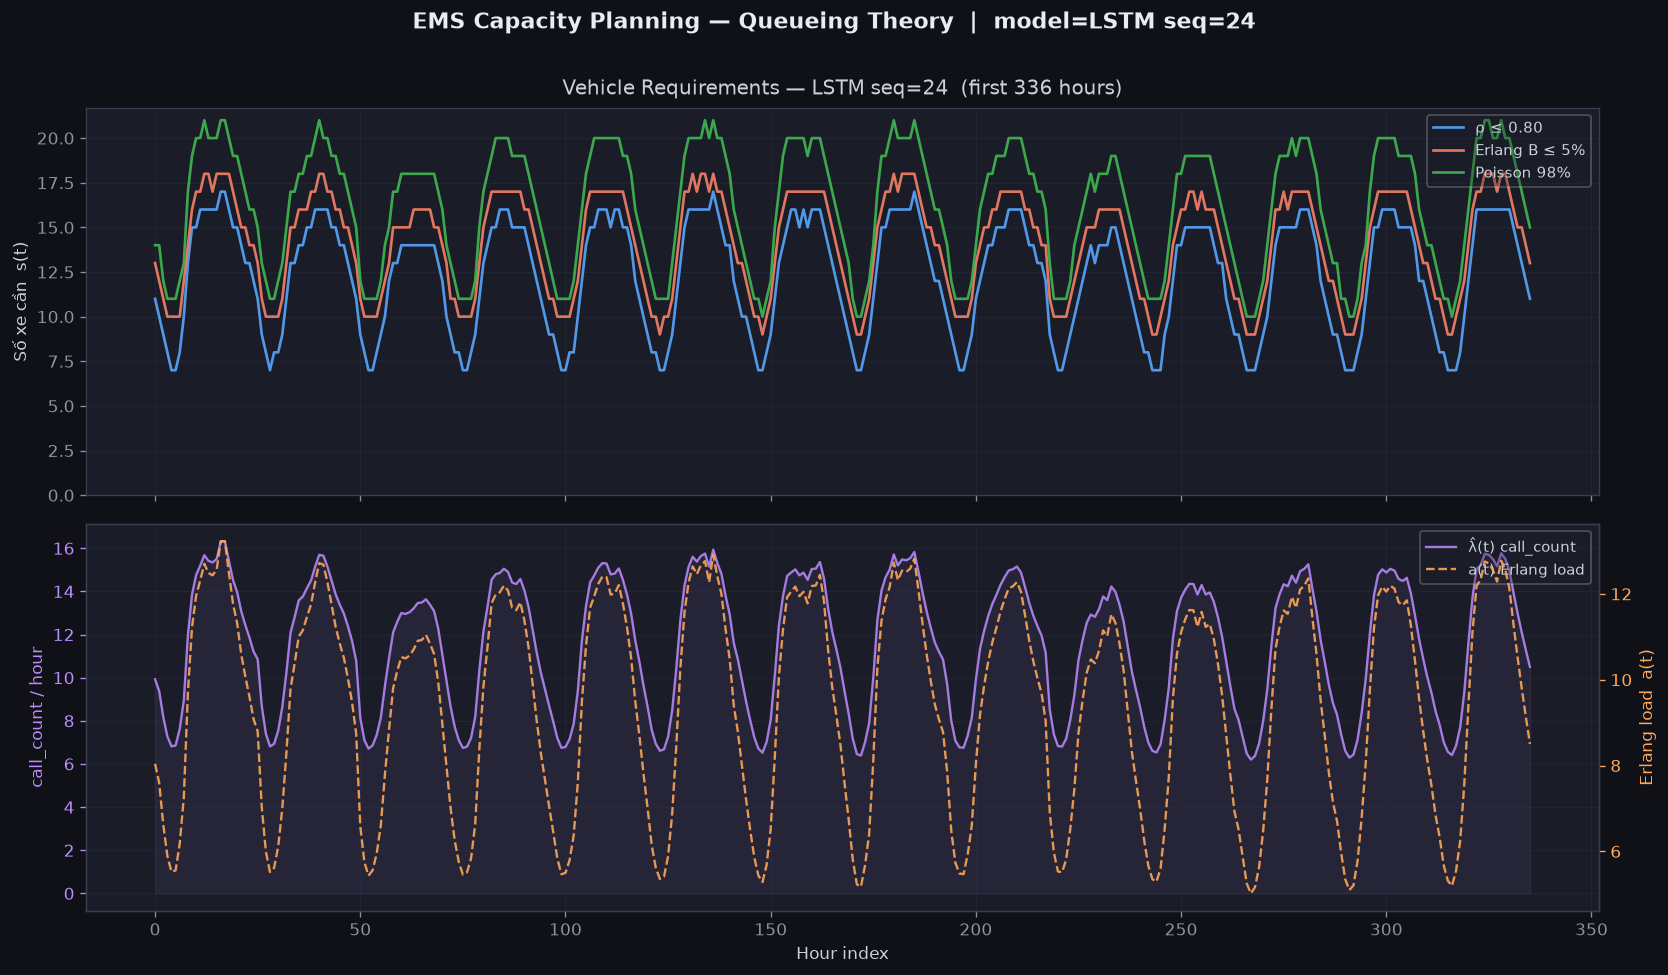

In [7]:
# Vẽ timeline cho LSTM seq=24
fig = plot_vehicles_timeline(
    df         = df_vehicles,
    model_name = "LSTM seq=24",
    n_hours    = 24 * 14,   # 14 ngày
    save_path  = os.path.join(OUTPUT_DIR, "vehicles_timeline_LSTM_seq24.png"),
)
plt.show()


### 6.2 Profile 24 Giờ — Nhu cầu Xe Trung bình theo Giờ trong Ngày
Biểu đồ này cực kỳ quan trọng cho các nhà quản lý để thiết kế **ca trực (shifts)** trong ngày:
* **Thấp điểm**: Đêm và sáng sớm (03:00 - 06:00).
* **Cao điểm**: Chiều và đầu giờ tối (14:00 - 20:00).

  [Queuing] Profile plot saved → f:\ems-forecast\outputs\vehicles_hourly_profile.png


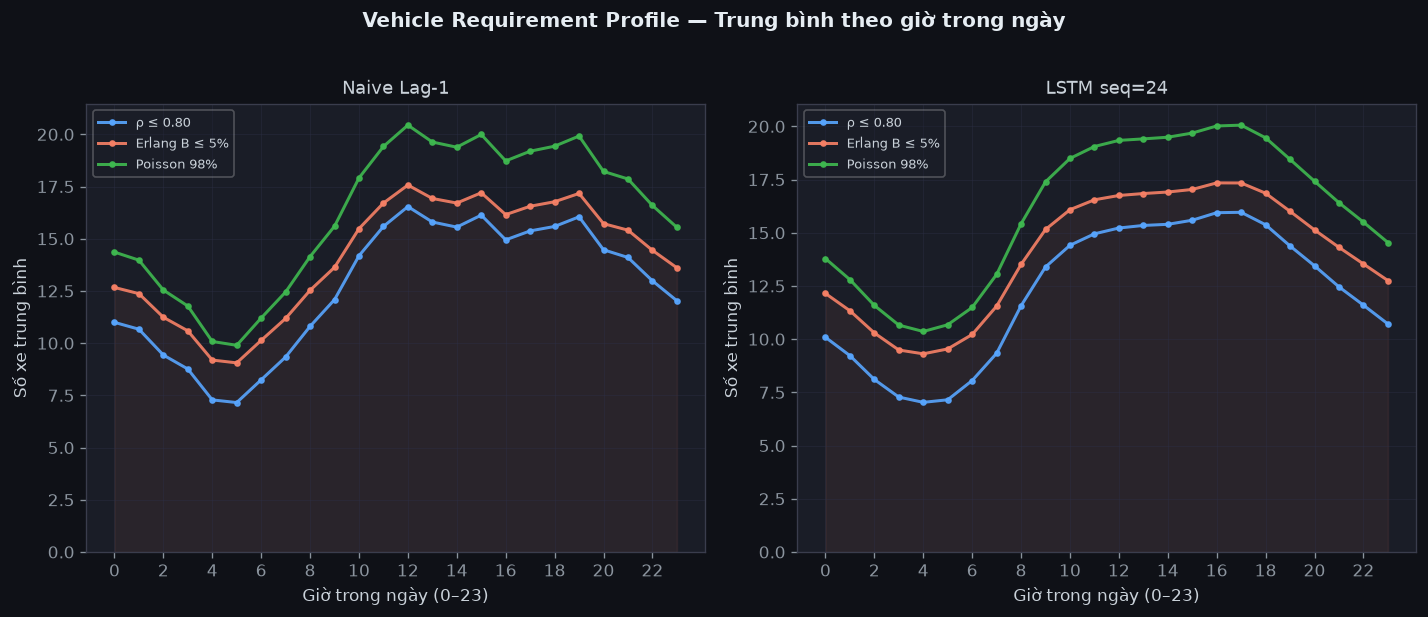

In [8]:
fig = plot_hourly_profile(
    df        = df_vehicles,
    save_path = os.path.join(OUTPUT_DIR, "vehicles_hourly_profile.png"),
)
plt.show()


## Bước 7: Phân tích Độ nhạy (Sensitivity Analysis)
Trong thực tế, điều kiện thời tiết xấu hoặc kẹt xe có thể làm tăng thời gian bận của xe $E[S]$, hoặc các sự cố nghiêm trọng có thể làm tăng số xe điều động $u$.
Ta tiến hành thử nghiệm biến thiên cả 2 tham số $\pm 20\%$ để đánh giá mức độ ảnh hưởng đến số xe cần bố trí.

In [ ]:
import itertools

base_model  = "LSTM seq=24"
lambda_base = y_pred_dict[base_model]

rows_sens = []
for e_fac, u_fac in itertools.product([0.8, 1.0, 1.2], [0.8, 1.0, 1.2]):
    E_S_try = params["E_S_hr"] * e_fac
    u_try   = params["u"]      * u_fac
    df_try  = forecast_to_vehicles({base_model: lambda_base},
                                    u=u_try, E_S_hr=E_S_try)
    agg = df_try.agg({
        "s_rho80":       "mean",
        "s_erlangB5pct": "mean",
        "s_poisson98":   "mean",
    }).to_dict()
    agg["E_S_factor"] = f"{e_fac:.1f}x"
    agg["u_factor"]   = f"{u_fac:.1f}x"
    rows_sens.append(agg)

df_sens = (pd.DataFrame(rows_sens)
             [["E_S_factor","u_factor","s_rho80","s_erlangB5pct","s_poisson98"]])
sens_path = os.path.join(OUTPUT_DIR, "sensitivity_analysis.csv")
df_sens.to_csv(sens_path, index=False)
print("Bảng Phân tích Độ nhạy — Số xe Trung bình (Mean) khi tham số thay đổi ±20%:")
df_sens


## Bước 8: Đề xuất Chiến lược Vận hành & Phân ca (Operational Shift Recommendations)

Dựa trên kết quả thực nghiệm lý thuyết hàng đợi:

1. **Lựa chọn Tiêu chuẩn Vận hành**:
   * **Tiêu chuẩn An toàn Khuyến nghị — Erlang B $\le 5\%$**: Trung bình cần **19 xe**, giờ cao điểm cần tối đa **31 xe**. Đây là tiêu chuẩn cân bằng tốt nhất giữa độ an toàn cho bệnh nhân và chi phí hoạt động của thành phố.
   * **Tiêu chuẩn Giờ Cao điểm / Khẩn cấp — Poisson 98%**: Trung bình cần **23 xe**, đỉnh điểm **35 xe**. Áp dụng trong các dịp lễ hội lớn, thời tiết cực đoan hoặc mùa dịch.

2. **Kế hoạch Phân ca Trực chiến (2 Ca 12 tiếng)**:
   * **Ca Ngày (07:00 - 19:00 — Cao điểm)**: Trung bình cần **22 - 25 xe**. Cần bố trí thêm các xe cơ động tại các khu vực trọng điểm nội đô.
   * **Ca Đêm (19:00 - 07:00 — Thấp điểm)**: Nhu cầu giảm xuống **14 - 17 xe**. Có thể rút bớt xe về trạm để bảo dưỡng kỹ thuật, khử khuẩn và cho nhân sự nghỉ ngơi.

3. **Lợi ích so với Naive Baseline**:
   * Mô hình LSTM seq=24 đón trước được xu hướng tăng tải trước 1-2 giờ, giúp xe có mặt sẵn sàng tại vị trí trực chiến trước khi cuộc gọi tăng đột biến.
